# Smart Microscopy — YOLOv8 Fixed-Cell Division Detection

**Task:** single-class object detection of dividing cells in still microscopy images  
**Annotation/data:** Roboflow  
**Model:** Ultralytics YOLOv8  
**Downstream use:** ROI export and cell-center coordinates for microscope targeting

| Section | Purpose |
|---|---|
| 1 · Setup | Colab, packages, imports |
| 2 · Dataset | Download Roboflow Version 2 and verify split/annotation counts |
| 3 · Training | Train with `no_aug`, `yolo_default`, or `custom` augmentation |
| 4 · Training review | Curves, confusion matrix, validation predictions |
| 5 · Validation | Optional quantitative evaluation on `val` or `test` |
| 6 · Fixed-image inference | Detect dividing cells and export coordinates/ROIs |
| 7 · Summary | Report current run paths and settings |

Tracking and temporal event extraction are intentionally omitted. They are not needed for the current fixed-cell experiment.

---
## 1 · Setup
Run once per Colab session.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!nvidia-smi
%pip install -q ultralytics roboflow pandas pyyaml

import json
import warnings
from datetime import datetime
from getpass import getpass
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

import ultralytics
from ultralytics import YOLO

ultralytics.checks()
warnings.filterwarnings('ignore')

IMAGE_EXTS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
print('Ready.')

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Setup complete ✅ (12 CPUs, 53.0 GB RAM, 47.4/235.7 GB disk)
Ready.


---
## 2 · Dataset

The API key is entered at runtime and is not stored in the notebook. The same cell also reports the actual exported split sizes, positive/negative images, and object counts.

**Important:** For a clean augmentation comparison, use a Roboflow version without generated augmentation.

In [3]:
from roboflow import Roboflow

RF_WORKSPACE = 'jakob-mastrandrea'
RF_PROJECT   = 'smartmic-m4lac'
RF_VERSION   = 2
DATASET_DIR  = Path('/content/smartmic_m4lac_v2')

DATA_YAML = DATASET_DIR / 'data.yaml'

if not DATA_YAML.exists():
    RF_API_KEY = getpass('Roboflow API key: ')
    rf = Roboflow(api_key=RF_API_KEY)
    project = rf.workspace(RF_WORKSPACE).project(RF_PROJECT)
    version = project.version(RF_VERSION)
    dataset = version.download('yolov8', location=str(DATASET_DIR))
    DATA_YAML = Path(dataset.location) / 'data.yaml'

if not DATA_YAML.exists():
    raise FileNotFoundError(f'data.yaml not found: {DATA_YAML}')

with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

names = data_cfg.get('names', [])
if isinstance(names, dict):
    class_names = [names[k] for k in sorted(names)]
else:
    class_names = list(names)

print(f'Dataset: {DATA_YAML}')
print(f'Classes: {class_names}')
if len(class_names) != 1:
    print(f'WARNING: expected a single detection class, found {len(class_names)}.')

rows = []
for split in ['train', 'valid', 'test']:
    image_dir = DATA_YAML.parent / split / 'images'
    label_dir = DATA_YAML.parent / split / 'labels'
    if not image_dir.exists():
        continue

    image_files = sorted([p for p in image_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS])
    positive_images = 0
    object_count = 0

    for image_path in image_files:
        label_path = label_dir / f'{image_path.stem}.txt'
        if label_path.exists():
            lines = [x for x in label_path.read_text().splitlines() if x.strip()]
            object_count += len(lines)
            positive_images += int(len(lines) > 0)

    rows.append({
        'split': split,
        'images': len(image_files),
        'positive_images': positive_images,
        'negative_images': len(image_files) - positive_images,
        'dividing_cell_instances': object_count,
    })

summary_df = pd.DataFrame(rows)
display(summary_df)
print(f'Total exported images: {summary_df["images"].sum() if len(summary_df) else 0}')
print(f'Total annotated instances: {summary_df["dividing_cell_instances"].sum() if len(summary_df) else 0}')

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/smartmic_m4lac_v2 in yolov8:: 100%|██████████| 286/286 [00:00<00:00, 11821.46it/s]

Dataset: /content/smartmic_m4lac_v2/data.yaml
Classes: ['event']


,split,images,positive_images,negative_images,dividing_cell_instances
0,train,131,131,0,182
1,valid,10,9,1,14


Total exported images: 141
Total annotated instances: 196


---
## 3 · Training

Set `AUG_MODE` to one of:

- `no_aug` — disables configurable YOLO augmentation and the default Albumentations transforms
- `yolo_default` — keeps the current Ultralytics defaults
- `custom` — microscopy-oriented transforms hard-coded below

Keep the test split untouched while choosing model size, image size, and augmentation mode. Use it only for the final comparison.

In [4]:
PROJECT_ROOT = '/content/SmartMicroscopy/YOLOv8'        #@param {type:"string"}
PROJECT_ROOT = Path(PROJECT_ROOT)
RESULTS_ROOT = PROJECT_ROOT / 'Results'
RUN_NAME     = 'SmartMic_YOLOv8'                                   #@param {type:"string"}

YOLO_SIZE    = 'n'                 #@param ["n","s","m","l","x"] {type:"string"}
EPOCHS       = 100                 #@param {type:"number"}
PATIENCE     = 30                  #@param {type:"number"}
BATCH_SIZE   = 4                   #@param {type:"number"}
IMGSZ        = 640                 #@param {type:"number"}
INITIAL_LR   = 0.001               #@param {type:"number"}
OPTIMIZER    = 'AdamW'             #@param ["auto","SGD","Adam","AdamW"] {type:"string"}
SEED         = 13                  #@param {type:"number"}
AUG_MODE     = 'no_aug'            #@param ["no_aug","yolo_default","custom"] {type:"string"}

# Hard-coded custom augmentation. Spatial orientation is arbitrary for fixed cells;
# intensity jitter is kept modest and mosaic/mixup are disabled.
CUSTOM_AUG = dict(
    degrees=180.0,
    translate=0.05,
    scale=0.10,
    shear=0.0,
    perspective=0.0,
    flipud=0.5,
    fliplr=0.5,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.10,
    mosaic=0.0,
    mixup=0.0,
    cutmix=0.0,
    augmentations=[],
)

NO_AUG = dict(
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    mosaic=0.0,
    mixup=0.0,
    cutmix=0.0,
    augmentations=[],
)

if AUG_MODE == 'no_aug':
    aug_kwargs = NO_AUG
elif AUG_MODE == 'yolo_default':
    aug_kwargs = {}
elif AUG_MODE == 'custom':
    aug_kwargs = CUSTOM_AUG
else:
    raise ValueError(f'Unknown AUG_MODE: {AUG_MODE}')

stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
EXPERIMENT_NAME = f'{RUN_NAME}_{AUG_MODE}_{stamp}'
RUN_DIR = RESULTS_ROOT / EXPERIMENT_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(f'yolov8{YOLO_SIZE}.pt')
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    batch=BATCH_SIZE,
    imgsz=IMGSZ,
    lr0=INITIAL_LR,
    optimizer=OPTIMIZER,
    seed=SEED,
    pretrained=True,
    plots=True,
    save=True,
    project=str(RUN_DIR),
    name='training',
    exist_ok=True,
    **aug_kwargs,
)

TRAIN_DIR = RUN_DIR / 'training'
PRETRAINED_MODEL = str(TRAIN_DIR / 'weights' / 'best.pt')

run_log = {
    'experiment': EXPERIMENT_NAME,
    'dataset': str(DATA_YAML),
    'model': f'yolov8{YOLO_SIZE}.pt',
    'imgsz': IMGSZ,
    'batch': BATCH_SIZE,
    'epochs_requested': EPOCHS,
    'patience': PATIENCE,
    'optimizer': OPTIMIZER,
    'initial_lr': INITIAL_LR,
    'seed': SEED,
    'augmentation': AUG_MODE,
    'best_model': PRETRAINED_MODEL,
}

LOG_FILE = RUN_DIR / 'run_log.json'
with open(LOG_FILE, 'w') as f:
    json.dump(run_log, f, indent=2)

print(f'Best model: {PRETRAINED_MODEL}')
print(f'Run directory: {RUN_DIR}')

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/smartmic_m4lac_v2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=training, nbs=64, nms=N

---
## 4 · Training review

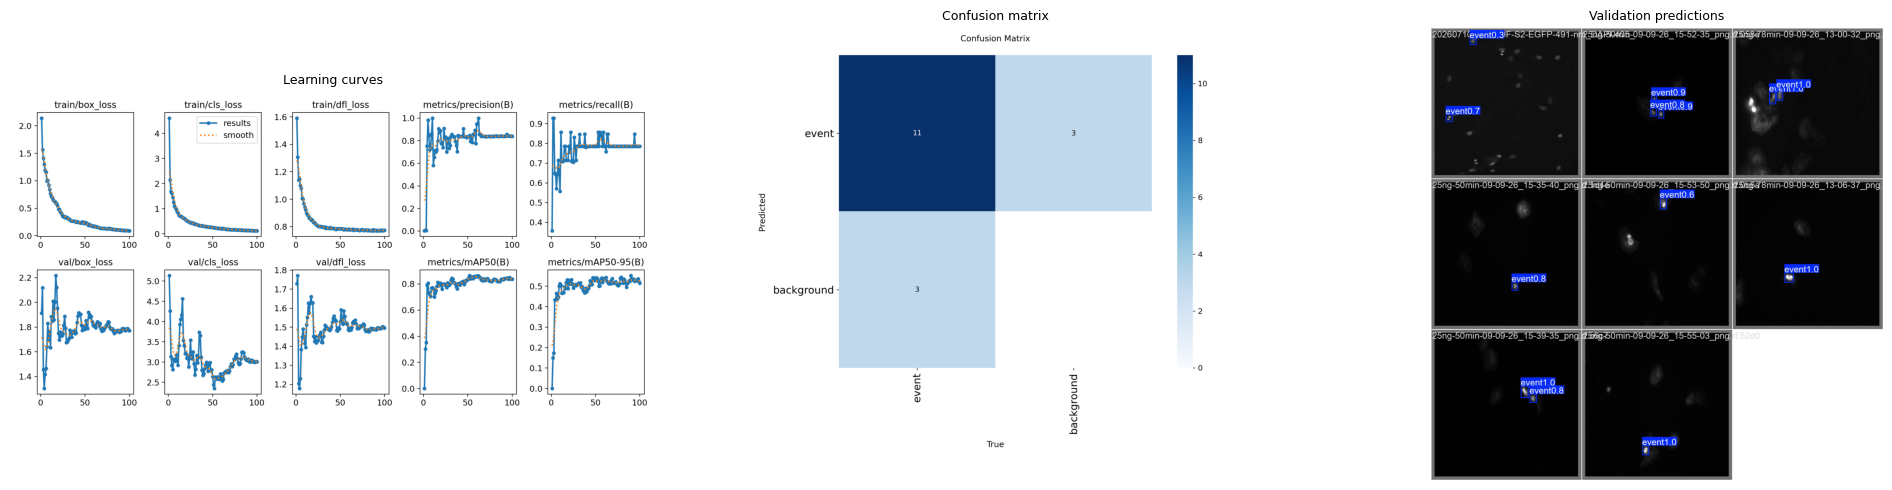

In [4]:
def show_image_or_message(ax, path, title):
    path = Path(path)
    if path.exists():
        ax.imshow(plt.imread(str(path)))
    else:
        ax.text(0.5, 0.5, f'Not found:\n{path.name}', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title, fontsize=9)
    ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
show_image_or_message(axes[0], TRAIN_DIR / 'results.png', 'Learning curves')
show_image_or_message(axes[1], TRAIN_DIR / 'confusion_matrix.png', 'Confusion matrix')
show_image_or_message(axes[2], TRAIN_DIR / 'val_batch0_pred.jpg', 'Validation predictions')
plt.tight_layout()
plt.show()

---
## 5 · Validation *(optional)*

For mAP/PR evaluation, keep `VAL_CONF` low. The operational confidence threshold for microscope use is tuned separately in Section 6.

Use `VAL_SPLIT = 'val'` during development. Change it to `test` only after the model/augmentation choice is fixed.

In [5]:
VAL_SPLIT = 'val'          #@param ["val","test"] {type:"string"}
VAL_CONF  = 0.10          #@param {type:"number"}
VAL_IOU   = 0.5            #@param {type:"number"}
VAL_IMGSZ = IMGSZ

val_model = YOLO(PRETRAINED_MODEL)
metrics = val_model.val(
    data=str(DATA_YAML),
    split=VAL_SPLIT,
    conf=VAL_CONF,
    iou=VAL_IOU,
    imgsz=VAL_IMGSZ,
    plots=True,
    project=str(RUN_DIR),
    name=f'validation_{VAL_SPLIT}',
    exist_ok=True,
)

val_summary = {
    'split': VAL_SPLIT,
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'mAP50': float(metrics.box.map50),
    'mAP50_95': float(metrics.box.map),
}
run_log['validation'] = val_summary
with open(LOG_FILE, 'w') as f:
    json.dump(run_log, f, indent=2)

print(f"Precision   : {val_summary['precision']:.4f}")
print(f"Recall      : {val_summary['recall']:.4f}")
print(f"mAP@0.5     : {val_summary['mAP50']:.4f}")
print(f"mAP@0.5:0.95: {val_summary['mAP50_95']:.4f}")

Ultralytics 8.4.152 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 421.8±204.7 MB/s, size: 7.5 KB)
val: Scanning /content/smartmic_m4lac_v2/valid/labels.cache... 10 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 3.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.9it/s 0.2s
                   all         10         14       0.84      0.786      0.813      0.524
Speed: 0.4ms preprocess, 9.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/SmartMicroscopy/YOLOv8/Results/SmartMic_YOLOv8_no_aug_20260915_102423/validation_val
Precision   : 0.8395
Recall      : 0.7857
mAP@0.5     : 0.8129
mAP@0.5:0.95: 0.5238


---
## 6 · Fixed-image inference and ROI export

Runs the trained detector on still images and exports:

- annotated images
- `detections.csv` with box coordinates, center coordinates, class, and confidence
- optional cropped ROIs

Coordinates are in pixels of the original input image. `center_x` and `center_y` are the values needed for downstream centering/targeting logic.

In [ ]:
INFER_INPUT            = '/content/drive/MyDrive/SmartMicroscopy/TestImages'  #@param {type:"string"}
USE_MODEL_FROM_THIS_RUN = True                                                #@param {type:"boolean"}
EXTERNAL_MODEL_PATH     = '/content/drive/MyDrive/SmartMicroscopy/YOLOv8/Models/best.pt'  #@param {type:"string"}
INFER_CONF             = 0.25                                                #@param {type:"number"}
INFER_IOU              = 0.5                                                 #@param {type:"number"}
INFER_IMGSZ            = IMGSZ
MAX_DET                = 100                                                 #@param {type:"number"}
SAVE_ROIS              = True                                                #@param {type:"boolean"}
N_PREVIEW              = 6                                                   #@param {type:"number"}

if USE_MODEL_FROM_THIS_RUN:
    if 'PRETRAINED_MODEL' not in globals():
        raise RuntimeError('No model from this run is available. Set USE_MODEL_FROM_THIS_RUN=False and provide EXTERNAL_MODEL_PATH.')
    MODEL_PATH = PRETRAINED_MODEL
else:
    MODEL_PATH = EXTERNAL_MODEL_PATH

input_path = Path(INFER_INPUT)
if not input_path.exists():
    raise FileNotFoundError(f'Inference input not found: {input_path}')

if 'RUN_DIR' in globals():
    infer_root = Path(RUN_DIR) / 'inference'
else:
    stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    infer_root = RESULTS_ROOT / f'inference_{stamp}'

annotated_root = infer_root / 'annotated'
roi_root = infer_root / 'rois'
annotated_root.mkdir(parents=True, exist_ok=True)
if SAVE_ROIS:
    roi_root.mkdir(parents=True, exist_ok=True)

infer_model = YOLO(MODEL_PATH)
rows = []
preview_pairs = []

results = infer_model.predict(
    source=str(input_path),
    conf=INFER_CONF,
    iou=INFER_IOU,
    imgsz=INFER_IMGSZ,
    max_det=MAX_DET,
    stream=True,
    verbose=False,
)

for result in results:
    src = Path(result.path)
    if input_path.is_dir():
        try:
            rel = src.relative_to(input_path)
        except ValueError:
            rel = Path(src.name)
    else:
        rel = Path(src.name)

    ann_path = (annotated_root / rel).with_suffix('.png')
    ann_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(ann_path), result.plot(line_width=2))
    preview_pairs.append((src, ann_path))

    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        continue

    xyxy = boxes.xyxy.cpu().numpy()
    confs = boxes.conf.cpu().numpy()
    classes = boxes.cls.cpu().numpy().astype(int)
    h, w = result.orig_img.shape[:2]

    for det_id, (box, conf, cls_id) in enumerate(zip(xyxy, confs, classes), start=1):
        x1, y1, x2, y2 = box.tolist()
        x1i = max(0, int(np.floor(x1)))
        y1i = max(0, int(np.floor(y1)))
        x2i = min(w, int(np.ceil(x2)))
        y2i = min(h, int(np.ceil(y2)))

        class_name = result.names[int(cls_id)]
        rows.append({
            'image': str(rel),
            'detection_id': det_id,
            'class_id': int(cls_id),
            'class_name': class_name,
            'confidence': float(conf),
            'x1': x1,
            'y1': y1,
            'x2': x2,
            'y2': y2,
            'center_x': (x1 + x2) / 2.0,
            'center_y': (y1 + y2) / 2.0,
            'width': x2 - x1,
            'height': y2 - y1,
        })

        if SAVE_ROIS and x2i > x1i and y2i > y1i:
            crop = result.orig_img[y1i:y2i, x1i:x2i]
            crop_dir = roi_root / rel.parent
            crop_dir.mkdir(parents=True, exist_ok=True)
            crop_path = crop_dir / f'{rel.stem}_det{det_id:03d}.png'
            cv2.imwrite(str(crop_path), crop)

columns = [
    'image', 'detection_id', 'class_id', 'class_name', 'confidence',
    'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'width', 'height'
]
detections_df = pd.DataFrame(rows, columns=columns)
csv_path = infer_root / 'detections.csv'
detections_df.to_csv(csv_path, index=False)

print(f'Images processed: {len(preview_pairs)}')
print(f'Detections: {len(detections_df)}')
print(f'CSV: {csv_path}')
if SAVE_ROIS:
    print(f'ROIs: {roi_root}')

display(detections_df.head(20))

n = min(N_PREVIEW, len(preview_pairs))
if n > 0:
    fig, axes = plt.subplots(n, 2, figsize=(12, 4 * n))
    if n == 1:
        axes = np.array([axes])

    for i, (raw_path, ann_path) in enumerate(preview_pairs[:n]):
        raw = cv2.imread(str(raw_path), cv2.IMREAD_UNCHANGED)
        if raw is None:
            axes[i, 0].text(0.5, 0.5, 'Could not read image', ha='center', va='center')
        else:
            if raw.ndim == 2:
                axes[i, 0].imshow(raw, cmap='gray')
            else:
                axes[i, 0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
        axes[i, 0].set_title(raw_path.name)
        axes[i, 0].axis('off')

        ann = cv2.imread(str(ann_path))
        axes[i, 1].imshow(cv2.cvtColor(ann, cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title('Prediction')
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

---
## 7 · Summary

In [ ]:
print('=' * 72)
if 'EXPERIMENT_NAME' in globals():
    print(f'Experiment       : {EXPERIMENT_NAME}')
    print(f'Augmentation     : {AUG_MODE}')
    print(f'Best model       : {PRETRAINED_MODEL}')
    print(f'Run directory    : {RUN_DIR}')
if 'val_summary' in globals():
    print(f"Validation split : {val_summary['split']}")
    print(f"mAP@0.5          : {val_summary['mAP50']:.4f}")
    print(f"mAP@0.5:0.95     : {val_summary['mAP50_95']:.4f}")
if 'csv_path' in globals():
    print(f'Inference CSV    : {csv_path}')
print('=' * 72)